# Machine Learning: Predicción de Volumen de Envíos

## 📌 Objetivo de Negocio
El objetivo de este modelo es predecir si un despacho será de **gran volumen** o **pequeño volumen** basándose en el proveedor y el día de la semana. Esto permite al área de logística dimensionar correctamente los transportes (camiones grandes vs. pequeños) y optimizar la planificación de carga, reduciendo costos operativos.

## 🎯 Definición del Target
Definimos un envío como **Grande (1)** si la cantidad solicitada supera la mediana histórica de todos los envíos. De lo contrario, será **Pequeño (0)**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Cargar el dataset limpio que guardamos en el módulo 1
ruta = '../01_data_explorer/data/despachos_limpios.csv'
df = pd.read_csv(ruta)

print(f"Dimensiones del dataset: {df.shape}")
df.head()

Dimensiones del dataset: (11663, 10)


,fecha_de_registro,n_oc,proveedor,descripcion_del_articulo,cantidad,fecha_de_salida_de_dinet,fecha_de_llegada_del_trasporte_a_mina,dias_transito,mes,dia_semana
0,2019-04-23 00:00:00,24566,PRECISION,Modulo de 4 canales,6,2019-04-29,2019-04-30,1,2019-04,Lunes
1,2019-04-23 00:00:00,24531,PROMELSA,Solvente para limpieza,20,2019-04-29,2019-04-30,1,2019-04,Lunes
2,2019-04-23 00:00:00,24580,PROMELSA,Terminal de 1/2,140,2019-04-29,2019-04-30,1,2019-04,Lunes
3,2019-04-23 00:00:00,24531,PROMELSA,Cinta silicona,30,2019-04-29,2019-04-30,1,2019-04,Lunes
4,2019-04-23 00:00:00,24614,SANDVIK,Bocina de pin,2,2019-04-29,2019-04-30,1,2019-04,Lunes


In [12]:
# 1. Crear un nuevo Target basado en la Cantidad (Volumen del envío)
# Primero limpiamos la cantidad como hicimos antes
df['cantidad_limpia'] = df['cantidad'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['cantidad_limpia'] = pd.to_numeric(df['cantidad_limpia'], errors='coerce').fillna(0)

# Definimos el Target: Si la cantidad es mayor a la mediana, es un envío "Grande" (1)
mediana = df['cantidad_limpia'].median()
df['envio_grande'] = np.where(df['cantidad_limpia'] > mediana, 1, 0)

print(f"Mediana de cantidad: {mediana}")
print("Distribución del nuevo Target (0=Pequeño, 1=Grande):")
print(df['envio_grande'].value_counts())

# 2. Variables predictoras (Features): Usaremos el Proveedor y el Día de la semana
df['fecha_de_salida_de_dinet'] = pd.to_datetime(df['fecha_de_salida_de_dinet'])
df['dia_semana'] = df['fecha_de_salida_de_dinet'].dt.dayofweek

features = ['proveedor', 'dia_semana']
X = df[features].copy()
y = df['envio_grande'].copy()

# Codificar el Proveedor
le = LabelEncoder()
X['proveedor'] = le.fit_transform(X['proveedor'].astype(str))

print("\nMuestra de las variables de entrada:")
X.head()

Mediana de cantidad: 5.0
Distribución del nuevo Target (0=Pequeño, 1=Grande):
envio_grande
0    6125
1    5538
Name: count, dtype: int64

Muestra de las variables de entrada:


,proveedor,dia_semana
0,426,0
1,436,0
2,436,0
3,436,0
4,496,0


## 2. Entrenamiento del Modelo
Usaremos un **Random Forest Classifier**, un algoritmo robusto y muy utilizado en la industria por su capacidad de manejar datos no lineales y su interpretabilidad.

In [13]:
# 1. Dividir en conjunto de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Instanciar y entrenar el modelo
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 3. Hacer predicciones
y_pred = model.predict(X_test)

print("¡Modelo entrenado con éxito!")

¡Modelo entrenado con éxito!


## 3. Evaluación del Modelo
¿Qué tan bueno es nuestro modelo? Analizamos su precisión (Accuracy) y su capacidad para detectar los retrasos reales.

Accuracy (Precisión global): 0.77

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78      1190
           1       0.79      0.72      0.75      1143

    accuracy                           0.77      2333
   macro avg       0.77      0.77      0.77      2333
weighted avg       0.77      0.77      0.77      2333



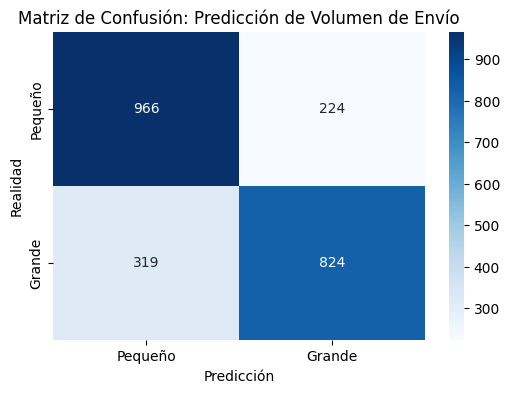

In [15]:
# 1. Accuracy (Precisión global)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (Precisión global): {accuracy:.2f}")

# 2. Reporte de clasificación (Precisión, Recall, F1-Score)
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

# 3. Matriz de Confusión visual
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Pequeño', 'Grande'], yticklabels=['Pequeño', 'Grande'])
plt.title('Matriz de Confusión: Predicción de Volumen de Envío')
plt.ylabel('Realidad')
plt.xlabel('Predicción')
plt.show()